# Segmentación de clientes (RFM) y valor de vida (CLV)

**Pregunta de negocio:** una tienda online de regalos (Reino Unido, venta sobre todo a otros comercios) quiere repartir mejor su presupuesto de marketing. Necesita saber:

1. ¿Quiénes son sus mejores clientes y quiénes se están yendo?
2. ¿Cuánto valdrá cada cliente el próximo año?
3. ¿Qué hacer con cada grupo?

**Datos:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) (UCI, CC BY 4.0). Son todas las ventas de la tienda entre diciembre de 2009 y diciembre de 2011: 1,07 millones de líneas de factura.

**Método:**
- **RFM** para segmentar: Recencia (cuándo compró por última vez), Frecuencia (cuántas veces) e iMporte (cuánto).
- **BG/NBD + Gamma-Gamma** para predecir el valor futuro. Son modelos probabilísticos clásicos de CLV que programo con scipy y valido con un periodo que el modelo no ha visto.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rfm.clv import BGNBD, GammaGamma, clv, resumen_cliente
from rfm.limpieza import cargar_crudo, limpiar, transacciones
from rfm.segmentos import ACCIONES, puntuar, resumen_segmentos, tabla_rfm

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold"})
AZUL, GRIS, ROJO, VERDE = "#1a56db", "#9ca3af", "#dc2626", "#059669"
IMG = "docs/img/"
CORTE = pd.Timestamp("2011-12-10")   # día siguiente a la última factura

## 1. Limpieza

In [2]:
crudo = cargar_crudo()
ventas, devoluciones, informe = limpiar(crudo)
informe

,paso,filas,filas_quitadas
0,Filas originales,1067371,0
1,Sin duplicados (las dos hojas se solapan en dic. 2010),1033036,34335
2,Con cliente identificado,797885,235151
3,"Solo productos (sin portes, comisiones ni vales)",794223,3662
4,"Ventas válidas (sin devoluciones, cantidades ni precios <= 0)",776577,17646


In [3]:
print(f"Clientes: {ventas['cliente'].nunique():,}  |  facturas: {ventas['factura'].nunique():,}  |  "
      f"ventas: £{ventas['importe'].sum():,.0f}")
print(f"Devoluciones: £{devoluciones['importe'].sum():,.0f} "
      f"({devoluciones['importe'].sum() / ventas['importe'].sum():.1%} de lo vendido)")
print(f"Reino Unido: {ventas.groupby('cliente')['pais'].first().eq('United Kingdom').mean():.0%} de los clientes")

Clientes: 5,852  |  facturas: 36,594  |  ventas: £17,068,568
Devoluciones: £709,953 (4.2% de lo vendido)
Reino Unido: 91% de los clientes


Decisiones:

- **Fuera el 23 % de líneas sin cliente.** No se pueden asignar a nadie, así que no sirven para segmentar.
- **Fuera los códigos que no son productos:** portes, comisiones de Amazon, ajustes contables y vales regalo.
- **Devoluciones (facturas que empiezan por C):** se guardan aparte y se restan del importe de cada cliente en el RFM.
- **Duplicados:** las dos hojas del Excel se solapan en diciembre de 2010; se quitan.

## 2. ¿Cuánto dependen las ventas de pocos clientes?

El 20 % de los clientes genera el 77% de las ventas; el 1 %, el 32%.


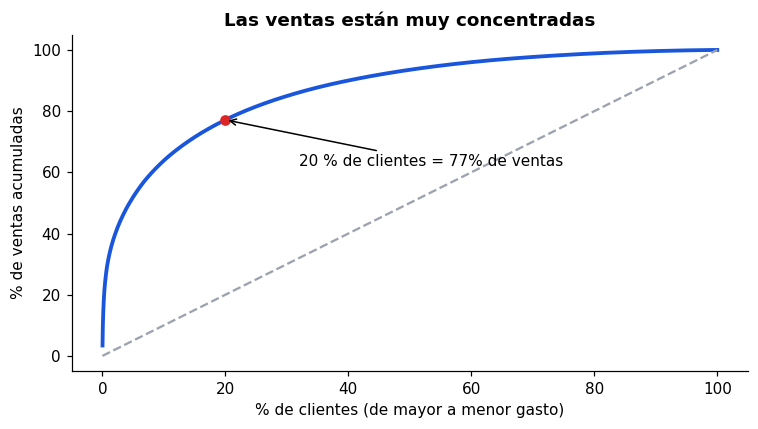

In [4]:
por_cliente = ventas.groupby("cliente")["importe"].sum().sort_values(ascending=False)
acumulado = por_cliente.cumsum() / por_cliente.sum()
pct_clientes = np.arange(1, len(por_cliente) + 1) / len(por_cliente)
top20 = acumulado.iloc[int(len(por_cliente) * 0.2) - 1]
top1 = acumulado.iloc[int(len(por_cliente) * 0.01) - 1]
print(f"El 20 % de los clientes genera el {top20:.0%} de las ventas; el 1 %, el {top1:.0%}.")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(100 * pct_clientes, 100 * acumulado.to_numpy(), color=AZUL, lw=2.5)
ax.plot([0, 100], [0, 100], ls="--", color=GRIS)
ax.scatter([20], [100 * top20], color=ROJO, zorder=3)
ax.annotate(f"20 % de clientes = {top20:.0%} de ventas", (20, 100 * top20), (32, 62),
            arrowprops={"arrowstyle": "->"})
ax.set_xlabel("% de clientes (de mayor a menor gasto)"); ax.set_ylabel("% de ventas acumuladas")
ax.set_title("Las ventas están muy concentradas")
fig.tight_layout(); fig.savefig(IMG + "concentracion.png"); plt.show()

## 3. Segmentación RFM

Cada cliente recibe una puntuación de 1 a 5 en recencia, frecuencia e importe, según el quintil en el que cae (5 = mejor). Con la recencia (R) y la frecuencia (F) se asigna uno de 10 segmentos clásicos. Por ejemplo, R = 5 y F = 4-5 son «Campeones», y R = 1-2 con F = 5 son «No se pueden perder».

Los empates son un problema: muchos clientes tienen una sola compra. Por eso los quintiles se calculan sobre el ranking y no sobre el valor, así que cada puntuación agrupa al 20 % de los clientes.

In [5]:
rfm = puntuar(tabla_rfm(ventas, devoluciones, CORTE))
rfm[["recencia", "frecuencia", "importe", "R", "F", "M", "segmento"]].describe(include="all").T.iloc[:, :6]

,count,unique,top,freq,mean,std
recencia,"5,852.00",NaN,NaN,NaN,200.73,208.52
frecuencia,"5,852.00",NaN,NaN,NaN,6.25,12.75
importe,"5,852.00",NaN,NaN,NaN,"2,795.89","13,825.19"
R,"5,852.00",NaN,NaN,NaN,3.00,1.41
F,"5,852.00",NaN,NaN,NaN,3.00,1.41
M,"5,852.00",NaN,NaN,NaN,3.00,1.41
segmento,5852,10,Hibernando,1511,NaN,NaN


In [6]:
seg = resumen_segmentos(rfm)
seg[["clientes", "pct_clientes", "pct_importe", "recencia_mediana", "frecuencia_media", "importe_medio"]]

,clientes,pct_clientes,pct_importe,recencia_mediana,frecuencia_media,importe_medio
segmento,,,,,,
Campeones,826,0.14,0.52,9.00,19.26,"10,353.07"
Leales,1155,0.20,0.28,53.00,9.78,"3,946.42"
Potencialmente leales,711,0.12,0.04,24.00,2.57,873.80
Nuevos,52,0.01,0.00,11.00,1.00,345.60
Prometedores,114,0.02,0.00,38.00,1.00,310.30
Necesitan atención,269,0.05,0.02,107.00,3.15,"1,240.13"
A punto de dormirse,384,0.07,0.01,92.50,1.36,522.10
No se pueden perder,72,0.01,0.03,315.50,16.36,"6,648.12"
En riesgo,758,0.13,0.06,376.00,3.90,"1,264.64"


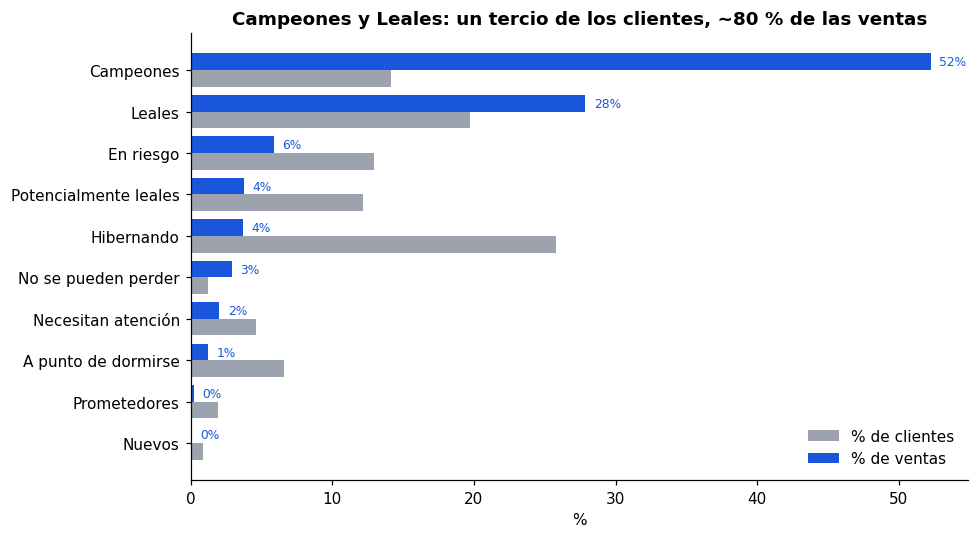

In [7]:
s = seg.sort_values("pct_importe")
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(s))
ax.barh(y - 0.2, 100 * s["pct_clientes"], height=0.4, color=GRIS, label="% de clientes")
ax.barh(y + 0.2, 100 * s["pct_importe"], height=0.4, color=AZUL, label="% de ventas")
ax.set_yticks(y, s.index)
for i, (c, v) in enumerate(zip(s["pct_clientes"], s["pct_importe"])):
    ax.text(100 * v + 0.6, i + 0.2, f"{v:.0%}", va="center", fontsize=8, color=AZUL)
ax.set_xlabel("%"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Campeones y Leales: un tercio de los clientes, ~80 % de las ventas")
fig.tight_layout(); fig.savefig(IMG + "segmentos.png"); plt.show()

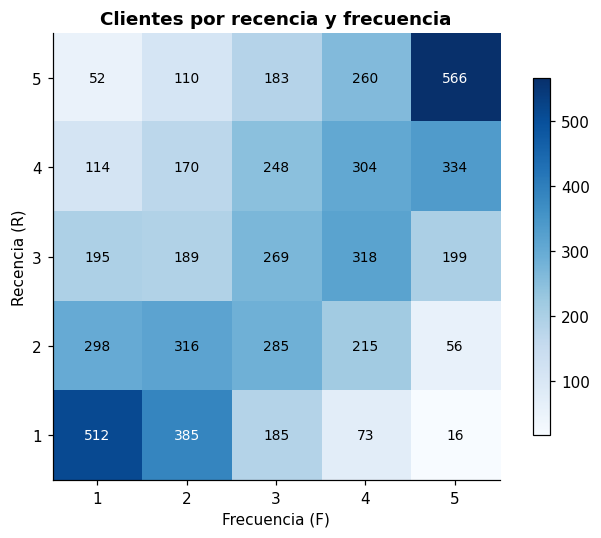

In [8]:
mapa = rfm.pivot_table(index="R", columns="F", values="importe", aggfunc="size").sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(mapa.values, cmap="Blues")
ax.set_xticks(range(5), mapa.columns); ax.set_yticks(range(5), mapa.index)
ax.set_xlabel("Frecuencia (F)"); ax.set_ylabel("Recencia (R)")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{mapa.values[i, j]:,.0f}", ha="center", va="center",
                color="white" if mapa.values[i, j] > mapa.values.max() * 0.6 else "black", fontsize=9)
ax.set_title("Clientes por recencia y frecuencia")
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout(); fig.savefig(IMG + "mapa_rf.png"); plt.show()

La diagonal del mapa domina. Quien compra a menudo suele haber comprado hace poco (arriba a la derecha), y quien compró una vez hace tiempo no vuelve (abajo a la izquierda). Las esquinas «raras» son las interesantes: arriba a la izquierda están los **nuevos** y abajo a la derecha los **buenos clientes que se han ido**.

## 4. Valor de vida del cliente (CLV)

El RFM mira al pasado. Para repartir presupuesto hace falta saber cuánto **va a** comprar cada cliente. Uso dos modelos:

- **BG/NBD:** cada cliente compra a su ritmo (Poisson) hasta que, sin avisar, deja de ser cliente (tras cada compra hay una probabilidad de irse). Con su historial (cuántas compras, cuándo fue la última y desde cuándo es cliente) estima cuántas compras hará y la **probabilidad de que siga activo**.
- **Gamma-Gamma:** estima cuánto gastará de media por compra. Combina la media del cliente con la de todos los clientes, y fía más de la del cliente cuantas más compras tiene.

Antes de usarlos compruebo si funcionan: **entreno hasta el 9 de junio de 2011 y predigo los 6 meses siguientes**, que el modelo no ha visto.

In [9]:
tr = transacciones(ventas)
corte_cal = pd.Timestamp("2011-06-10")
semanas_val = (CORTE - corte_cal).days / 7

cal = resumen_cliente(tr, corte_cal)
bg_cal = BGNBD().ajustar(cal["x"], cal["t_x"], cal["T"])
gg_cal = GammaGamma().ajustar(cal["x"], cal["m"])

real = (tr[(tr["dia"] >= corte_cal) & (tr["dia"] < CORTE)]
        .groupby("cliente").agg(compras=("dia", "size"), gasto=("importe", "sum")))
val = clv(bg_cal, gg_cal, cal, semanas_val).join(real).fillna({"compras": 0, "gasto": 0})

# Dos predicciones de referencia sencillas para comparar
ultimos6 = tr[(tr["dia"] >= corte_cal - pd.Timedelta(weeks=26)) & (tr["dia"] < corte_cal)]
val["ref_ultimos_6_meses"] = ultimos6.groupby("cliente")["importe"].sum().reindex(val.index).fillna(0)
historico = tr[tr["dia"] < corte_cal].groupby("cliente")["importe"].sum()
val["ref_media_historica"] = historico.reindex(val.index) / val["T"] * semanas_val

print(f"Clientes en calibración: {len(cal):,}")
print(f"Compras en los 6 meses de validación: reales {val['compras'].sum():,.0f}  |  predichas {val['compras_esperadas'].sum():,.0f}")
print(f"Gasto: real £{val['gasto'].sum():,.0f}  |  predicho £{val['clv'].sum():,.0f}")

Clientes en calibración: 4,944
Compras en los 6 meses de validación: reales 7,753  |  predichas 7,603
Gasto: real £4,522,860  |  predicho £3,671,239


In [10]:
def metricas(col):
    top = val.nlargest(int(len(val) * 0.2), col)["gasto"].sum() / val["gasto"].sum()
    return {"predicción": col, "error_medio_por_cliente": (val[col] - val["gasto"]).abs().mean(),
            "total_predicho": val[col].sum(), "correlación_de_orden": val[[col, "gasto"]].corr("spearman").iloc[0, 1],
            "gasto_real_del_top20_predicho": top}

pd.DataFrame([metricas(c) for c in ["clv", "ref_ultimos_6_meses", "ref_media_historica"]]).set_index("predicción")

,error_medio_por_cliente,total_predicho,correlación_de_orden,gasto_real_del_top20_predicho
predicción,,,,
clv,608.09,"3,671,238.66",0.63,0.73
ref_ultimos_6_meses,612.82,"3,163,500.92",0.57,0.72
ref_media_historica,900.58,"6,335,172.88",0.58,0.72


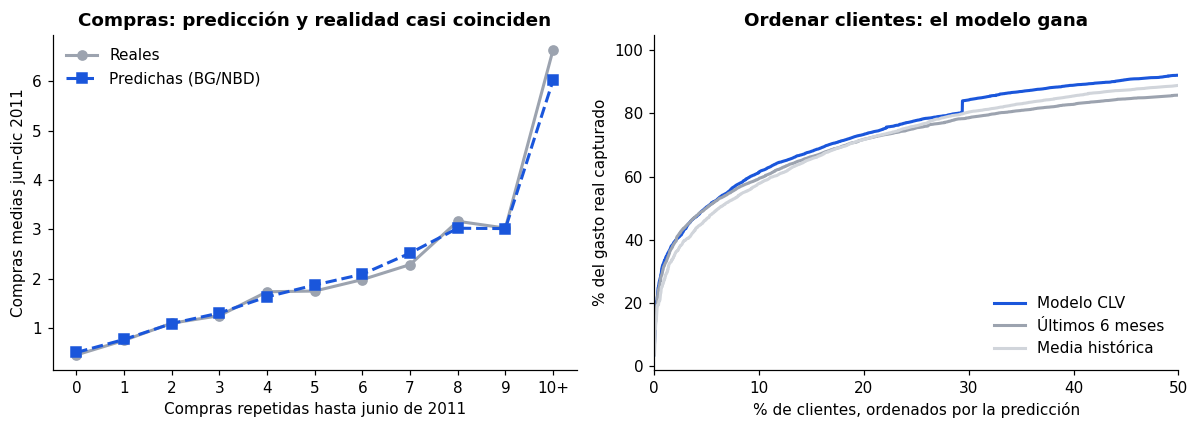

In [11]:
val["grupo_frecuencia"] = val["x"].clip(upper=10)
por_f = val.groupby("grupo_frecuencia")[["compras", "compras_esperadas"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(por_f.index, por_f["compras"], "o-", color=GRIS, lw=2, label="Reales")
ax.plot(por_f.index, por_f["compras_esperadas"], "s--", color=AZUL, lw=2, label="Predichas (BG/NBD)")
ax.set_xticks(range(11), [str(i) for i in range(10)] + ["10+"])
ax.set_xlabel("Compras repetidas hasta junio de 2011"); ax.set_ylabel("Compras medias jun-dic 2011")
ax.set_title("Compras: predicción y realidad casi coinciden"); ax.legend(frameon=False)

ax = axes[1]
for col, nombre, color in [("clv", "Modelo CLV", AZUL), ("ref_ultimos_6_meses", "Últimos 6 meses", GRIS),
                           ("ref_media_historica", "Media histórica", "#d1d5db")]:
    orden = val.sort_values(col, ascending=False)["gasto"].cumsum() / val["gasto"].sum()
    ax.plot(100 * np.arange(1, len(orden) + 1) / len(orden), 100 * orden.to_numpy(), label=nombre, color=color, lw=2)
ax.set_xlim(0, 50)
ax.set_xlabel("% de clientes, ordenados por la predicción"); ax.set_ylabel("% del gasto real capturado")
ax.set_title("Ordenar clientes: el modelo gana"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(IMG + "validacion.png"); plt.show()

**Cómo lo hace el modelo en los 6 meses que no vio:**

- **Compras:** casi exacto en total (-2 %) y en cada grupo de frecuencia.
- **Gasto total:** se queda corto, un -19 %. En la validación el ticket medio subió un 10 % respecto al año anterior (en 2010, en el mismo periodo, no subió), y el modelo supone que cada cliente mantiene su gasto medio. Para **presupuestar el total** hay que tenerlo en cuenta.
- **Ordenar clientes,** que es para lo que se usa en marketing: el 20 % que el modelo marca como más valioso concentra el **73 % del gasto real**, más que con las dos predicciones de referencia. También tiene la mayor correlación de orden y el menor error por cliente.

Un supuesto que conviene revisar: Gamma-Gamma asume que el importe por compra no depende de la frecuencia.

In [12]:
repiten = cal[cal["x"] > 0]
print(f"Correlación entre frecuencia e importe medio (clientes que repiten): {repiten[['x', 'm']].corr().iloc[0, 1]:.3f}")

Correlación entre frecuencia e importe medio (clientes que repiten): 0.081


Correlación casi nula: el supuesto se cumple.

### Modelo final: valor de los próximos 12 meses

Vuelvo a entrenar con todos los datos hasta diciembre de 2011 y predigo 52 semanas. El CLV está en **ventas** (libras), no en margen, porque el dataset no trae costes.

In [13]:
todos = resumen_cliente(tr, CORTE)
bg = BGNBD().ajustar(todos["x"], todos["t_x"], todos["T"])
gg = GammaGamma().ajustar(todos["x"], todos["m"])
futuro = clv(bg, gg, todos, 52)
clientes = rfm.join(futuro[["prob_activo", "compras_esperadas", "importe_esperado", "clv"]])
print(f"BG/NBD: r={bg.r:.3f}, alpha={bg.alpha:.2f}, a={bg.a:.3f}, b={bg.b:.3f}")
print(f"Gamma-Gamma: p={gg.p:.2f}, q={gg.q:.2f}, v={gg.v:.1f}")
print(f"Ventas brutas esperadas en 12 meses: £{clientes['clv'].sum():,.0f}")

BG/NBD: r=0.669, alpha=9.15, a=0.111, b=2.445
Gamma-Gamma: p=2.23, q=3.49, v=443.6
Ventas brutas esperadas en 12 meses: £8,953,747


**Las devoluciones importan.** Los modelos trabajan con compras, no con devoluciones. El caso extremo es el cliente 12346: compró 74.215 unidades de un artículo por 77.000 £ y lo devolvió todo, pero sin corregir aparecería como uno de los clientes más valiosos. Descuento a cada cliente su tasa histórica de devolución.

In [14]:
clientes["tasa_devolucion"] = (clientes["devuelto"] / clientes["importe_bruto"]).clip(0, 1)
clientes["clv_bruto"] = clientes["clv"]
clientes["clv"] = clientes["clv_bruto"] * (1 - clientes["tasa_devolucion"])
print(clientes.loc[12346, ["importe_bruto", "devuelto", "clv_bruto", "clv"]].round(0).to_string())
print(f"\nVentas netas esperadas de los clientes actuales en 12 meses: £{clientes['clv'].sum():,.0f}")

importe_bruto   77,353.00
devuelto        77,184.00
clv_bruto       28,631.00
clv                 63.00

Ventas netas esperadas de los clientes actuales en 12 meses: £8,551,548


In [15]:
por_segmento = clientes.groupby("segmento").agg(
    clientes=("clv", "size"),
    prob_activo_media=("prob_activo", "mean"),
    clv_medio=("clv", "mean"),
    clv_total=("clv", "sum"),
)
por_segmento["pct_clv"] = por_segmento["clv_total"] / por_segmento["clv_total"].sum()
por_segmento = por_segmento.reindex(seg.index)
por_segmento["accion"] = por_segmento.index.map(ACCIONES)
por_segmento

,clientes,prob_activo_media,clv_medio,clv_total,pct_clv,accion
segmento,,,,,,
Campeones,826,0.99,"5,298.63","4,376,672.02",0.51,"Premiar: acceso anticipado, programa VIP. Pueden ser embajadores."
Leales,1155,0.96,"1,905.70","2,201,082.46",0.26,Venta cruzada y de mayor valor; pedirles reseñas.
Potencialmente leales,711,0.96,"1,088.27","773,757.33",0.09,Programa de fidelización y recomendaciones personalizadas.
Nuevos,52,1.00,"1,161.18","60,381.33",0.01,Buena bienvenida: guía de producto y oferta para la 2.ª compra.
Prometedores,114,1.00,880.86,"100,417.96",0.01,Dar a conocer el catálogo; ofertas de entrada.
Necesitan atención,269,0.93,684.61,"184,160.14",0.02,Ofertas por tiempo limitado basadas en su historial.
A punto de dormirse,384,0.97,560.12,"215,085.26",0.03,Reactivar con contenido y descuentos antes de perderlos.
No se pueden perder,72,0.31,557.44,"40,135.93",0.00,Contacto directo y personal: eran de los mejores y se han ido.
En riesgo,758,0.67,386.68,"293,105.15",0.03,Campaña de recuperación con incentivo fuerte.


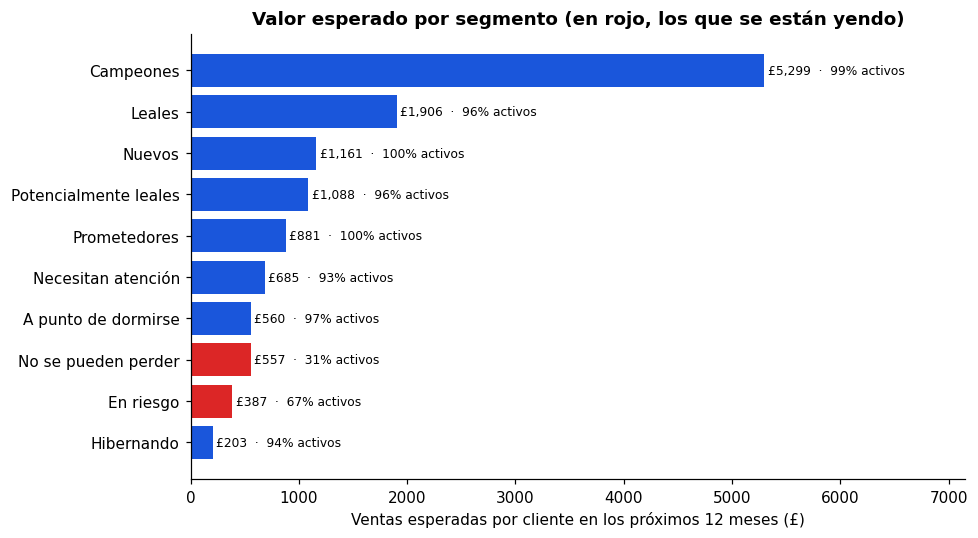

In [16]:
s = por_segmento.sort_values("clv_medio")
fig, ax = plt.subplots(figsize=(9, 5))
colores = [ROJO if n in ("No se pueden perder", "En riesgo") else AZUL for n in s.index]
ax.barh(s.index, s["clv_medio"], color=colores)
for i, (v, p) in enumerate(zip(s["clv_medio"], s["prob_activo_media"])):
    ax.text(v + 30, i, f"£{v:,.0f}  ·  {p:.0%} activos", va="center", fontsize=8)
ax.set_xlabel("Ventas esperadas por cliente en los próximos 12 meses (£)")
ax.set_xlim(0, s["clv_medio"].max() * 1.35)
ax.set_title("Valor esperado por segmento (en rojo, los que se están yendo)")
fig.tight_layout(); fig.savefig(IMG + "clv_segmentos.png"); plt.show()

**Ojo con la «probabilidad de seguir activo» de Hibernando.** El BG/NBD solo deja de dar por activo a un cliente cuando ha repetido compra y luego deja de comprar. Quien compró una sola vez cuenta como activo por definición del modelo. Por eso Hibernando, con una compra hace más de un año, sale con un 94 % de activos. Su valor esperado sí es bajo (~200 £), porque el modelo usa el ritmo de compra de toda la población, que en ellos es lento. Para estos clientes manda el valor esperado, no la probabilidad.

### A quién llamar primero

Los segmentos «En riesgo» y «No se pueden perder» no han comprado en meses, pero muchos de sus clientes **siguen activos según el modelo** y tienen un valor esperado alto. Son los primeros a los que contactar, ordenados por valor esperado:

In [17]:
prioridad = (clientes[clientes["segmento"].isin(["No se pueden perder", "En riesgo"])]
             .sort_values("clv", ascending=False))
print(f"{len(prioridad):,} clientes en riesgo, con £{prioridad['clv'].sum():,.0f} de ventas esperadas en 12 meses. "
      f"Los 100 primeros suman £{prioridad['clv'].head(100).sum():,.0f}.")
prioridad[["pais", "recencia", "frecuencia", "importe", "prob_activo", "clv"]].head(10)

830 clientes en riesgo, con £333,241 de ventas esperadas en 12 meses. Los 100 primeros suman £118,178.


,pais,recencia,frecuencia,importe,prob_activo,clv
cliente,,,,,,
15749,United Kingdom,236,3,"21,535.90",0.83,"6,179.96"
13952,United Kingdom,218,14,"12,790.89",0.76,"3,986.92"
15032,United Kingdom,257,8,"10,515.05",0.83,"3,325.75"
14828,United Kingdom,197,13,"9,803.46",0.77,"3,174.07"
14439,Greece,320,5,"9,443.04",0.79,"2,511.05"
14154,United Kingdom,240,8,"6,263.60",0.87,"2,339.80"
17504,United Kingdom,207,18,"9,238.42",0.52,"2,280.45"
14105,United Kingdom,240,5,"5,703.98",0.90,"2,053.53"
14442,Channel Islands,205,7,"5,272.02",0.91,"1,936.03"


## 5. Conclusiones y recomendaciones

1. **Las ventas dependen de pocos clientes.** El 20 % genera ~3/4 de las ventas. Campeones y Leales (un tercio de los clientes) concentran ~80 % de las ventas y la mayor parte del valor futuro. Prioridad: **no perderlos** (atención personal, condiciones preferentes).
2. **La recuperación tiene una lista concreta.** Los clientes «En riesgo» y «No se pueden perder» con más valor esperado son el mejor uso del presupuesto de retención: valen mucho y el modelo dice que muchos siguen activos.
3. **No gastar de más en «Hibernando».** Una cuarta parte de los clientes, con muy poco valor esperado: basta una reactivación barata por email.
4. **Convertir a los Nuevos en recurrentes:** la segunda compra es el gran salto. Un incentivo para la segunda compra es la acción más rentable con ellos.
5. **Usar el CLV para ordenar, no para presupuestar al detalle.** El modelo ordena bien a los clientes (el top 20 % predicho captura el 73 % del gasto real), pero en la validación infravaloró el gasto total un 19 % por la subida del ticket.

## 6. Limitaciones

- **CLV en ventas, no en margen,** porque no hay costes.
- **Muchos clientes son mayoristas,** con compras grandes y regulares. Los modelos funcionan, pero un CLV por cliente de miles de libras no es el de un consumidor final.
- **Dos años de datos,** con una sola Navidad de validación.
- **Los segmentos RFM son relativos** (quintiles): cambian si cambia la base de clientes.